# Phase 6 — The one evaluation on the test set (2025-01 → 2026-08)

**Question:** on the day a CVE is published, can we pick the ones attackers will exploit within 90 days better than
today's rules, at the same emergency-patching capacity?

**How this was run (TEST PROTOCOL in CLAUDE.md, fixed before the test set was opened):**
* Headline = **gradient boosting** (Decision 12, chosen on dev evidence only); alternative = **late fusion**
  (gradient boosting + text MLP). Both refit once on all of dev (2022-01 → 2024-12), frozen, sha256-checked.
* Main metric: **recall@110 per calendar month** (share of exploited CVEs caught when patching 110 CVEs a month),
  also K = 305; paired within-month bootstrap (2,000 resamples) for 95% CIs and differences.
* The test set was scored **once** (`src/phase6_test.py --test --confirm-phase6`). This notebook only reads those
  cached results; nothing here re-fits or re-scores the frozen models.
* Sections 1–6 are **pre-registered**. Sections 7–8 are **post-test exploratory** and are labelled as such.

In [1]:
import os, sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "mpl"))
warnings.filterwarnings("ignore", category=UserWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt

FIG, TAB = ROOT / "outputs" / "figures", ROOT / "outputs" / "tables"
BLUE, ORANGE, AQUA, VIOLET, INK, INK2, GRID, SURF = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 11, "font.size": 9.5})
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
def save(fig, name): fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
def T(name): return pd.read_csv(TAB / f"{name}.csv")
SHORT = {"gradient boosting (headline)": "gradient\nboosting", "late fusion (alternative)": "late\nfusion",
         "phrase, then CVSS (CNA)": "phrase, then\nCVSS (CNA)", "CVSS (CNA) ranking": "CVSS (CNA)\nranking",
         "EPSS (first score, <=7 d after pub)": "EPSS\n(<= 7 d)"}

HEAD, ALT = "gradient boosting (headline)", "late fusion (alternative)"
EPSS7, EPSS1, EPSS0 = "EPSS (first score, <=7 d after pub)", "EPSS (score by day 1)", "EPSS (day-0 score only)"
COL = {HEAD: BLUE, ALT: AQUA, "phrase, then CVSS (CNA)": ORANGE, "CVSS (CNA) ranking": INK2,
       "generous CVSS (fallback) ranking": "#999999", EPSS7: VIOLET, EPSS1: "#a196e8", EPSS0: "#d2cdf4", "random": "#cccccc"}
sc = pd.read_parquet(ROOT / "data" / "phase6_scores_test.parquet")
months = sc["published"].dt.to_period("M")
print(f"test: {len(sc):,} CVEs, {int(sc['label'].sum())} exploited within 90 days ({sc['label'].mean():.2%}), "
      f"{months.nunique()} months ({sc['published'].min():%Y-%m-%d} -> {sc['published'].max():%Y-%m-%d})")
print(f"CVEs per month: {len(sc) / months.nunique():,.0f} on average (dev: 2,607) -> K = 110 is "
      f"{100 * 110 / (len(sc) / months.nunique()):.1f}% of a test month (dev: 4.2%)")

test: 102,561 CVEs, 294 exploited within 90 days (0.29%), 20 months (2025-01-01 -> 2026-08-20)
CVEs per month: 5,128 on average (dev: 2,607) -> K = 110 is 2.1% of a test month (dev: 4.2%)


## 1. Main result: recall at fixed capacity
Each method ranks every month's CVEs; we patch the top K and count the exploited CVEs caught. EPSS is shown three
ways: the first score within 7 days of publication (**lookahead: favours EPSS**, our models use day-0 information
only), the score available by day 1, and day-0 scores only (like-for-like).

,recall@110 [95% CI],recall@305 [95% CI],PR-AUC
method,,,
gradient boosting (headline),33.7 [28–39],49.3 [44–55],0.053
late fusion (alternative),29.3 [24–35],48.0 [43–54],0.048
"phrase, then CVSS (CNA)",25.2 [20–30],42.2 [36–48],0.042
CVSS (CNA) ranking,18.6 [14–23],36.1 [30–41],0.014
generous CVSS (fallback) ranking,17.8 [13–22],31.6 [26–37],0.015
"EPSS (first score, <=7 d after pub)",29.6 [24–35],45.4 [40–51],0.069
EPSS (score by day 1),29.6 [24–35],45.1 [39–51],0.069
EPSS (day-0 score only),5.1 [3–8],9.9 [7–14],0.003
random,2.2,6.2,0.003


difference [95% CI]                       P(headline better)      
K                                                     110                   305                110   305
headline minus                                                                                          
CVSS (CNA) ranking                    +15.1 [+8.8, +21.5]   +13.2 [+6.6, +20.1]               100%  100%
EPSS (day-0 score only)              +28.5 [+22.2, +34.5]  +39.4 [+32.5, +46.3]               100%  100%
EPSS (first score, <=7 d after pub)    +4.1 [-2.7, +10.5]    +3.9 [-3.1, +11.5]                86%   86%
EPSS (score by day 1)                  +4.1 [-2.7, +10.5]    +4.2 [-2.9, +11.7]                86%   88%
generous CVSS (fallback) ranking      +15.8 [+8.9, +22.4]  +17.7 [+11.0, +24.6]               100%  100%
late fusion (alternative)               +4.3 [-1.0, +9.1]     +1.4 [-4.1, +6.6]                94%   64%
phrase, then CVSS (CNA)                +8.5 [+1.7, +15.3]    +7.1 [+0.3, +14.2]                99%   98%

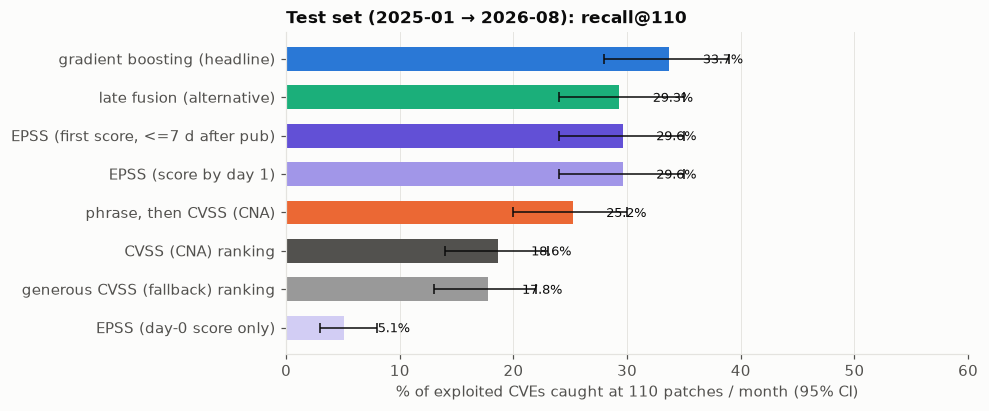

In [2]:
rec = T("06_recall").set_index("method")
show = rec[["recall@110 [95% CI]", "recall@305 [95% CI]", "PR-AUC"]].copy()
show.loc["random", ["recall@110 [95% CI]", "recall@305 [95% CI]"]] = [f"{rec.loc['random', 'recall@110']:.1f}", f"{rec.loc['random', 'recall@305']:.1f}"]
display(show.round({"PR-AUC": 3}))
d = T("06_diffs")
d["difference [95% CI]"] = [f"{r['diff (pts)']:+.1f} [{r['CI lo']:+.1f}, {r['CI hi']:+.1f}]" for _, r in d.iterrows()]
d["P(headline better)"] = (100 * d["P(headline better)"]).round(0).astype(int).astype(str) + "%"
display(d.pivot(index="headline minus", columns="K", values=["difference [95% CI]", "P(headline better)"]))

order = [HEAD, ALT, EPSS7, EPSS1, "phrase, then CVSS (CNA)", "CVSS (CNA) ranking", "generous CVSS (fallback) ranking", EPSS0]
ci = rec.loc[order, "recall@110 [95% CI]"].str.extract(r"([\d.]+) \[(\d+)–(\d+)\]").astype(float)
fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(order))[::-1]
ax.barh(y, ci[0], color=[COL[m] for m in order], height=0.62)
ax.errorbar(ci[0], y, xerr=[ci[0] - ci[1], ci[2] - ci[0]], fmt="none", ecolor=INK, lw=1, capsize=3)
for yi, v in zip(y, ci[0]): ax.annotate(f"{v:.1f}%", (v, yi), xytext=(22, -3), textcoords="offset points", fontsize=8.5)
ax.set_yticks(y, order); ax.grid(axis="y", visible=False); ax.set_xlim(0, 60)
ax.set_xlabel("% of exploited CVEs caught at 110 patches / month (95% CI)")
ax.set_title("Test set (2025-01 → 2026-08): recall@110", loc="left")
save(fig, "06_01_recall_at_110")

**Takeaway**: On 102,561 test CVEs (294 exploited), **gradient boosting catches 33.7% [28–39] of exploited CVEs at 110 patches a month**, against **25.2% [20–30] for the best day-0 rule** (+8.5 points [+1.7, +15.3], P(better) 99%) and **18.6% for today's CVSS ranking** (+15.1 [+8.8, +21.5]). At K = 305: 49.3% vs 42.2% and 36.1%. Against **EPSS with lookahead (29.6%) the lead is +4.1 points [−2.7, +10.5], P 86%: ahead, but not clearly**. EPSS has the higher PR-AUC (0.069 vs 0.053), which is driven by its top ranks. Like-for-like, EPSS with day-0 scores only catches 5.1%, because 70% of CVEs have no EPSS score until the day after publication. Late fusion (29.3%) is 4.3 points behind the headline [−1.0, +9.1]. All test numbers are below validation (headline 47.1% on val).

## 2. Same capacity as today's rules
Each rule uses its **own** test-period capacity (how many CVEs it flags per month); the models get exactly that
many patches.

In [3]:
own = T("06_own_capacity").set_index("rule")
display(own.round(1))

,patches/month,rule recall %,rule precision %,headline recall % at same K,late fusion recall % at same K
rule,,,,,
CVSS>=9 (CNA),385,41.2,1.6,51.7,55.4
CVSS>=7 (CNA),2068,77.6,0.6,87.8,91.5
phrase OR CVSS>=9 (CNA),387,47.3,1.8,51.7,55.4
generous CVSS>=9 (fallback),516,44.9,1.3,56.5,62.6


**Takeaway**: Today's rule, **CVSS ≥ 9 (CNA), now flags 385 CVEs a month** on test (196 on val, 110 on train) and catches **41.2%**. Gradient boosting with the same 385 patches catches **51.7%** (fusion 55.4%), about **+10 points for the same work**. Against 'phrase OR CVSS ≥ 9' (387/month, 47.3%) the gain is +4.4 points. Against the generous fallback rule (516/month, 44.9%) it is +11.6 points (56.5%).

## 3. Recall vs capacity on test
The full curve, so no single K drives the conclusion (K = 110 and 305 marked; fixed in Phase 4 from train).

,gradient boosting (headline),late fusion (alternative),"EPSS (first score, <=7 d after pub)","phrase, then CVSS (CNA)",CVSS (CNA) ranking
K per month,,,,,
50,21.1,18.0,22.4,18.5,11.7
110,33.7,29.3,29.6,25.2,18.6
200,41.2,40.5,37.4,33.1,26.5
305,49.3,48.0,45.4,42.2,36.1
500,55.8,60.9,52.4,52.1,46.3
1000,73.1,77.6,63.9,66.8,61.4


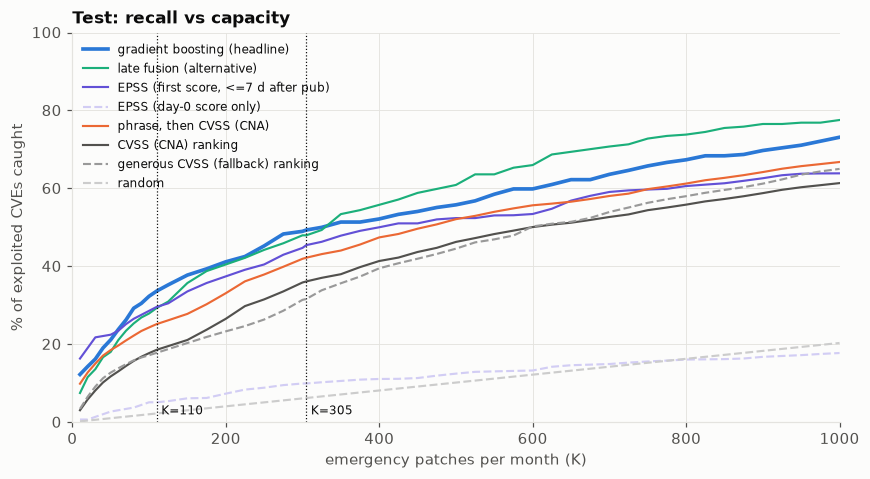

In [4]:
curve = T("06_recall_vs_k").set_index("K per month")
fig, ax = plt.subplots(figsize=(9, 4.6))
for m in [HEAD, ALT, EPSS7, EPSS0, "phrase, then CVSS (CNA)", "CVSS (CNA) ranking", "generous CVSS (fallback) ranking", "random"]:
    ax.plot(curve.index, 100 * curve[m], color=COL[m], lw=2.4 if m == HEAD else 1.4,
            ls="--" if m in ("generous CVSS (fallback) ranking", "random", EPSS0) else "-", label=m)
for k in (110, 305):
    ax.axvline(k, color=INK, lw=0.8, ls=":"); ax.annotate(f"K={k}", (k, 2), fontsize=8, xytext=(3, 0), textcoords="offset points")
ax.set(xlim=(0, 1000), ylim=(0, 100), xlabel="emergency patches per month (K)", ylabel="% of exploited CVEs caught")
ax.legend(frameon=False, fontsize=8, loc="upper left"); ax.set_title("Test: recall vs capacity", loc="left")
save(fig, "06_02_recall_vs_k")
display((100 * curve.loc[[50, 110, 200, 305, 500, 1000], [HEAD, ALT, EPSS7, "phrase, then CVSS (CNA)", "CVSS (CNA) ranking"]]).round(1))

**Takeaway**: Gradient boosting beats both day-0 rules at every capacity from 10 to 1,000 patches a month (e.g. 21.1 vs 18.5 at 50; 73.1 vs 66.8 at 1,000). **EPSS (with lookahead) leads only at very small K**: 16.3 vs 12.2 at 10/month and 22.4 vs 21.1 at 50. That is EPSS's high PR-AUC, which comes from its very top ranks. **From about 80 patches a month the model leads, and the gap widens with K**: +4.1 at 110, +3.9 at 305, +9.2 at 1,000. Late fusion overtakes gradient boosting above ~350/month (60.9 vs 55.8 at 500), which matches its stronger @305 on dev.

## 4. The EPSS comparison and its caveats
EPSS (FIRST) is the industry benchmark, but the comparison is not like-for-like:
1. **Lookahead.** Most CVEs get their first EPSS score the day *after* NVD publication; the ≤ 7-day line uses it anyway.
2. **Different target.** EPSS predicts exploitation activity in the next 30 days, not KEV listing within 90 days.
3. **Model change inside test.** EPSS v4 replaced v3 on 2025-03-17.
4. **EPSS may use the label.** *Assumption (FIRST documentation not reachable from the sandbox): EPSS v3/v4 list
   CISA KEV among their data sources, so an EPSS score dated after a CVE's KEV addition may reflect the label.*
   → Section 5.

In [5]:
cov = T("06_epss_coverage").set_index("first EPSS score at")
cov["share of positives %"] = 100 * cov["positives"] / cov["positives"].sum()
display(cov.round(1))
display(T("06_epss_v3_v4").set_index("EPSS model period"))

,negatives,positives,share of CVEs %,share of positives %
first EPSS score at,,,,
0 d,30562,62,29.9,21.1
1 d,71039,230,69.5,78.2
2 d,223,0,0.2,0.0
3 d,146,2,0.1,0.7
4 d,203,0,0.2,0.0
5 d,85,0,0.1,0.0
none within 7 d,9,0,0.0,0.0


,CVEs,positives,months,gradient boosting (headline) @110,late fusion (alternative) @110,"phrase, then CVSS (CNA) @110","EPSS (first score, <=7 d after pub) @110",EPSS (score by day 1) @110
EPSS model period,,,,,,,,
before 2025-03-17 (EPSS v3),9742,44,3,43.2 [29–59],46.6 [30–63],26.9 [14–40],40.9 [26–56],40.9 [26–56]
from 2025-03-17 (EPSS v4),92819,250,18,32.8 [27–39],27.5 [22–33],25.3 [20–31],30.8 [25–36],30.8 [25–36]


**Takeaway**: Only **29.9% of test CVEs have an EPSS score on publication day** (62 of 294 exploited); 69.5% get their first score the next day, and 9 CVEs get none within 7 days. So 'EPSS by day 1' ≈ 'EPSS within 7 days' (29.6% both), while 'day-0 only' is 5.1%. **During EPSS v3** (to 2025-03-17, 44 exploited) the headline scores 43.2% vs EPSS 40.9%. **During v4** (250 exploited) it scores 32.8% vs 30.8%. The gap is similar under both EPSS versions.

## 5. "Not yet in KEV": removing the label leak from the EPSS comparison (pre-registered)
For each EPSS line, an exploited CVE counts **only if CISA added it to KEV strictly after the date of the EPSS
score that line uses**. Exploited CVEs already in KEV by then are dropped from the evaluation for **every** method
(no credit, no capacity slot), so all methods are scored on the same CVEs.

,"@110, cut by EPSS (first score, <=7 d after pub) (185 kept, 109 dropped)","@110, cut by EPSS (day-0 score only) (280 kept, 14 dropped)",all exploited CVEs (Section 1)
gradient boosting (headline),30.4 [24–37],34.2 [28–40],33.7 [28–39]
late fusion (alternative),23.8 [17–29],29.0 [24–34],29.3 [24–35]
"phrase, then CVSS (CNA)",29.4 [23–36],25.9 [20–31],25.2 [20–30]
CVSS (CNA) ranking,22.1 [16–28],19.3 [14–24],18.6 [14–23]
generous CVSS (fallback) ranking,20.3 [14–27],18.2 [14–23],17.8 [13–22]
"EPSS (first score, <=7 d after pub)",14.6 [9–20],30.7 [26–36],29.6 [24–35]
EPSS (score by day 1),14.6 [9–20],30.7 [26–36],29.6 [24–35]
EPSS (day-0 score only),6.5 [3–10],4.3 [2–7],5.1 [3–8]


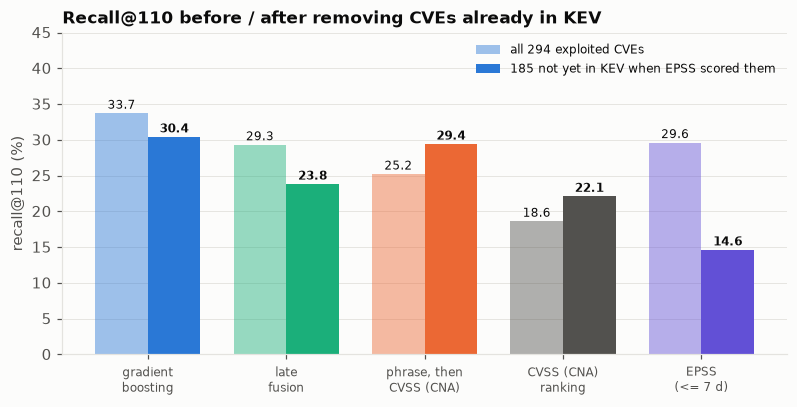

In [6]:
nyk = T("06_not_yet_in_kev").set_index("EPSS variant defining the cut")
methods = [HEAD, ALT, "phrase, then CVSS (CNA)", "CVSS (CNA) ranking", "generous CVSS (fallback) ranking", EPSS7, EPSS1, EPSS0]
tbl = pd.DataFrame({cut: {m: nyk.loc[cut, f"{m} @110"] for m in methods} for cut in [EPSS7, EPSS0]})
tbl.columns = [f"@110, cut by {c} ({nyk.loc[c, 'positives kept']} kept, {nyk.loc[c, 'positives dropped (KEV on/before EPSS date)']} dropped)" for c in tbl.columns]
tbl["all exploited CVEs (Section 1)"] = rec.loc[methods, "recall@110 [95% CI]"]
display(tbl)

pt = lambda s: float(s.split()[0])
plot_m = [HEAD, ALT, "phrase, then CVSS (CNA)", "CVSS (CNA) ranking", EPSS7]
fig, ax = plt.subplots(figsize=(8.5, 3.8))
x = np.arange(len(plot_m)); w = 0.38
a = [pt(rec.loc[m, "recall@110 [95% CI]"]) for m in plot_m]; b = [pt(nyk.loc[EPSS7, f"{m} @110"]) for m in plot_m]
ax.bar(x - w/2, a, w, color=[COL[m] for m in plot_m], alpha=0.45, label="all 294 exploited CVEs")
ax.bar(x + w/2, b, w, color=[COL[m] for m in plot_m], label="185 not yet in KEV when EPSS scored them")
for xi, (u, v) in enumerate(zip(a, b)):
    ax.annotate(f"{u:.1f}", (xi - w/2, u), ha="center", xytext=(0, 3), textcoords="offset points", fontsize=8)
    ax.annotate(f"{v:.1f}", (xi + w/2, v), ha="center", xytext=(0, 3), textcoords="offset points", fontsize=8, weight="bold")
ax.set_xticks(x, [SHORT[m] for m in plot_m], fontsize=8); ax.grid(axis="x", visible=False)
ax.set_ylabel("recall@110 (%)"); ax.set_ylim(0, 45); ax.legend(frameon=False, fontsize=8, loc="upper right")
ax.set_title("Recall@110 before / after removing CVEs already in KEV", loc="left")
save(fig, "06_03_not_yet_in_kev")

**Takeaway**: **109 of the 294 exploited test CVEs (37%) were already in KEV when EPSS produced the score used.** On the remaining 185, **EPSS falls from 29.6% to 14.6% [9–20]**, while **gradient boosting keeps 30.4% [24–37]** and the best rule 29.4%. That makes the headline ~2x EPSS on the CVEs where the label can't have leaked into EPSS. The same pattern held on val (EPSS 10.0% vs headline 52.5%, pre-test). With the day-0 cut only 14 CVEs drop (280 kept): headline 34.2%, EPSS day-0 4.3%. This rests on the stated assumption that EPSS uses KEV. Even without that assumption, a score dated after the KEV listing isn't something a team has on day 0.

## 6. Robustness (pre-registered): walk-forward 2022-24 → 2025, quarters, seeds, calibration
The headline was trained on all of dev (2022–2024), so **test year 2025 is the walk-forward fold 2022-24 → 2025**;
2026 is a further 8 months out.

In [7]:
byy = T("06_by_year").set_index("year")
display(byy)
byq = T("06_by_quarter").set_index("quarter")
display(byq)
seeds = T("06_seeds").set_index("text seed"); display(seeds.round(1))

,CVEs,positives,months,gradient boosting (headline) @110,late fusion (alternative) @110,"phrase, then CVSS (CNA) @110","EPSS (first score, <=7 d after pub) @110",EPSS (score by day 1) @110
year,,,,,,,,
2025,48150,159,12,41.9 [34–50],39.1 [31–47],29.5 [22–37],29.6 [23–37],29.6 [23–37]
2026,54411,135,8,23.9 [17–32],17.8 [12–25],20.0 [13–27],29.6 [21–37],29.6 [21–37]


,CVEs,positives,months,gradient boosting (headline) @110,late fusion (alternative) @110,"phrase, then CVSS (CNA) @110","EPSS (first score, <=7 d after pub) @110",EPSS (score by day 1) @110
quarter,,,,,,,,
2025Q1,11946,46,3,39.1 [23–52],40.2 [26–55],23.3 [11–36],23.9 [12–36],23.9 [12–36]
2025Q2,11695,42,3,44.4 [31–61],39.7 [25–54],33.8 [19–49],35.7 [21–50],35.7 [21–50]
2025Q3,11725,36,3,38.9 [21–56],38.9 [21–53],31.3 [17–48],25.0 [12–42],25.0 [12–42]
2025Q4,12784,35,3,45.7 [29–63],37.1 [22–54],30.8 [14–47],34.3 [18–51],34.3 [18–51]
2026Q1,15152,40,3,37.8 [23–54],52.5 [37–69],18.1 [6–32],47.5 [31–62],47.5 [31–62]
2026Q2,20688,56,3,25.3 [15–38],5.4 [0–13],28.3 [16–41],21.4 [11–33],21.4 [11–33]
2026Q3,18571,39,2,7.7 [0–18],0.0 [0–0],10.3 [2–21],23.1 [11–36],23.1 [11–36]


,recall@110,recall@305
text seed,,
0,28.2,49.0
1,29.3,48.0
2,28.9,47.6
3,29.6,48.6
4,29.9,48.5
mean,29.2,48.3
worst,28.2,47.6
5-seed ensemble (late fusion),29.3,48.0


**Takeaway**: **Walk-forward 2022-24 → 2025 (test year 2025): 41.9% [34–50]**, in line with gradient boosting's dev periods (WF 2023 39.7, WF 2024-H1 55.6, val 47.1). **2026 (Jan–Aug): 23.9% [17–32]**. By quarter the headline holds 37.8–45.7% from 2025Q1 to 2026Q1, then drops to **25.3% in 2026Q2 and 7.7% in 2026Q3** (Jul 1–Aug 20; 39 exploited). Late fusion collapses further (5.4% and 0.0%). The text-MLP seeds are stable (fusion 28.2–29.9% per seed vs 29.3% ensemble). The uncertain-phrase check was N/A on test (0 uncertain rows).

### Calibration of the headline probability (descriptive)
The calibrator (Platt on logit of the gradient-boosting score, Decision 12) was fit on dev's pooled out-of-time
scores and is **not refit on test**. Bins = percentiles of the score.

,0
Brier (calibrated),0.002816
Brier (constant base rate),0.002858
log loss (calibrated),0.016924
log loss (constant),0.019645
mean predicted,0.004154
observed rate,0.002867
note,out-of-sample


,score percentile bin,n,positives,predicted,observed
0,"[0.0, 0.5)",51280,24,0.08,0.05
1,"[0.5, 0.9)",41022,93,0.44,0.23
2,"[0.9, 0.95)",5129,54,1.35,1.05
3,"[0.95, 0.98)",3069,51,2.15,1.66
4,"[0.98, 0.99)",1066,18,2.73,1.69
5,"[0.99, 0.995)",482,15,3.21,3.11
6,"[0.995, 1.0)",513,39,4.38,7.60


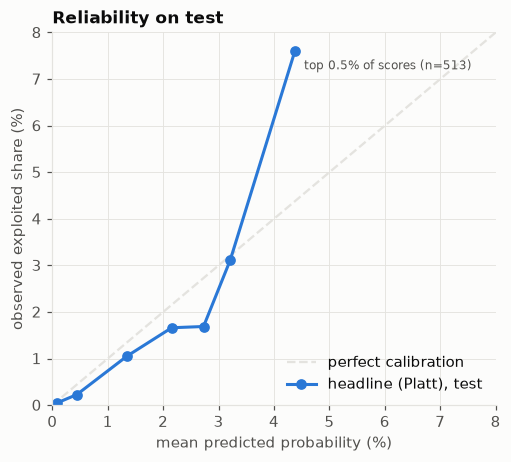

In [8]:
cal = T("06_calibration"); display(cal.T)
bins = T("06_calibration_bins").rename(columns={"s_hgb": "score percentile bin"})
display(bins.assign(predicted=lambda d: (100 * d["predicted"]).round(2), observed=lambda d: (100 * d["observed"]).round(2)))
fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.plot([0, 8], [0, 8], color=GRID, lw=1.5, ls="--", label="perfect calibration")
ax.plot(100 * bins["predicted"], 100 * bins["observed"], "o-", color=BLUE, lw=2, label="headline (Platt), test")
r = bins.iloc[-1]
ax.annotate(f"top 0.5% of scores (n={r['n']:,})", (100 * r["predicted"], 100 * r["observed"]), fontsize=8, xytext=(6, -12), textcoords="offset points", color=INK2)
ax.set(xlabel="mean predicted probability (%)", ylabel="observed exploited share (%)", xlim=(0, 8), ylim=(0, 8))
ax.legend(frameon=False, loc="lower right"); ax.set_title("Reliability on test", loc="left")
save(fig, "06_04_calibration")

**Takeaway**: Out of sample, the calibrated probability is only modestly better than a constant: **Brier 0.002816 vs 0.002858**, log loss 0.0169 vs 0.0196. It **over-predicts on average (0.42% predicted vs 0.29% observed)**, because the base rate fell from 0.34% (dev) to 0.29%. In the **top 0.5% of scores it under-predicts: 4.4% predicted vs 7.6% observed**. Ranking is what the model is used for; the probability is a rough guide and should be recalibrated when the model is retrained.

## 7. Why does recall fall in 2026? (post-test exploratory)
> ⚠️ **POST-TEST EXPLORATORY ANALYSIS.** Designed after the test results were seen. It explains the results; it changes **no** reported Phase 6 number and no model, K, metric or comparator.

Three questions: does **everyone** drop (or only our model)? Is it **volume** (a fixed K = 110 covering a shrinking
share of each month)? Did the **mix** of exploited CVEs change (new vendors, vendors without KEV history)?
Computed by `src/post_test_analysis.py` (log `outputs/logs/step9_post_test.log`).

year,2025,2026
positives,159,135
gradient boosting (headline) @110,41.9 [34–50],23.9 [17–32]
late fusion (alternative) @110,39.1 [31–47],17.8 [12–25]
"phrase, then CVSS (CNA) @110",29.5 [22–37],20.0 [13–27]
CVSS (CNA) ranking @110,19.2 [13–26],17.8 [11–25]
"EPSS (first score, <=7 d after pub) @110",29.6 [23–37],29.6 [21–37]
EPSS (score by day 1) @110,29.6 [23–37],29.6 [21–37]
random @110,2.7,1.7


,months,CVEs / month,exploited / month,K=110 as % of monthly CVEs,CVSS>=9 (CNA) / month,CVEs from vendors with earlier KEV entries / month
period,,,,,,
dev 2022-24,36,2606.7,8.9,4.2,123.8,695.7
2025,12,4012.5,13.2,2.7,237.5,1246.2
2026,8,6801.4,16.9,1.6,606.0,2375.8


year,2025,2026
budget,4.22% of each month's CVEs (= 110 in an average dev month),4.22% of each month's CVEs (= 110 in an average dev month)
patches / month (avg),169.321839,287.008429
gradient boosting (headline),49.685535,34.074074
late fusion (alternative),48.427673,34.074074
"phrase, then CVSS (CNA)",33.77705,31.230792
CVSS (CNA) ranking,23.359133,29.093736
"EPSS (first score, <=7 d after pub)",38.903287,39.091954
EPSS (score by day 1),38.903287,39.259259


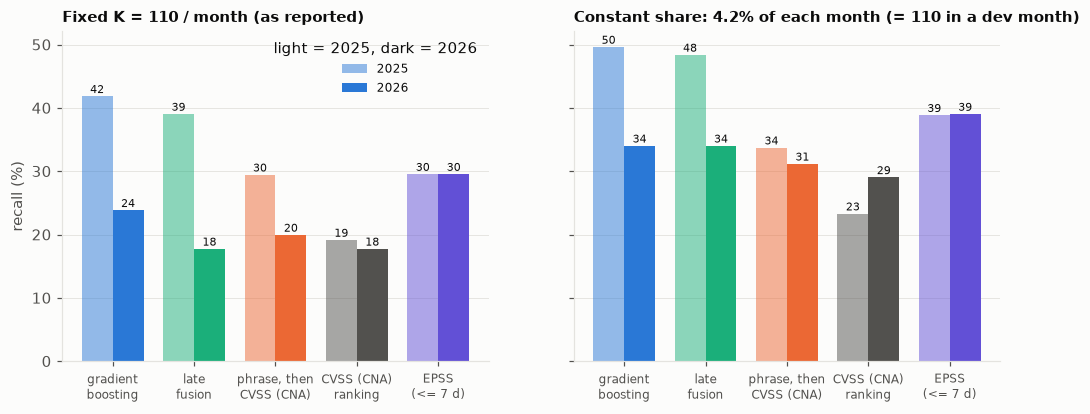

In [9]:
dy = T("06x_drift_by_year").set_index("year"); display(dy.T)
vol = T("06x_drift_volume").set_index("period"); display(vol.round(1))
cs = T("06x_drift_constant_share").set_index("year"); display(cs.T)

ms = [HEAD, ALT, "phrase, then CVSS (CNA)", "CVSS (CNA) ranking", EPSS7]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
for ax, (title, get) in zip(axes, [("Fixed K = 110 / month (as reported)", lambda m, y: pt(dy.loc[y, f"{m} @110"])),
                                   ("Constant share: 4.2% of each month (= 110 in a dev month)", lambda m, y: cs.loc[y, m])]):
    x = np.arange(len(ms)); w = 0.38
    for j, (yr, alpha) in enumerate([(2025, 0.5), (2026, 1.0)]):
        v = [get(m, yr) for m in ms]
        ax.bar(x + (j - 0.5) * w, v, w, color=[COL[m] for m in ms], alpha=alpha, label=str(yr))
        for xi, vi in zip(x, v): ax.annotate(f"{vi:.0f}", (xi + (j - 0.5) * w, vi), ha="center", xytext=(0, 2), textcoords="offset points", fontsize=7.5)
    ax.set_xticks(x, [SHORT[m] for m in ms], fontsize=8); ax.grid(axis="x", visible=False)
    ax.set_title(title, loc="left", fontsize=10)
axes[0].set_ylabel("recall (%)"); axes[0].legend(frameon=False, title="light = 2025, dark = 2026", fontsize=8)
save(fig, "06_05_drift_by_year")

**Takeaway**: **Not everyone drops.** At fixed K = 110, gradient boosting falls 41.9 → 23.9, fusion 39.1 → 17.8 and the best rule 29.5 → 20.0. CVSS ranking is flat (19.2 → 17.8) and **EPSS is flat (29.6 → 29.6)**. **Volume is a large part of it**: CVEs per month went 2,607 (dev) → 4,013 (2025) → 6,801 (2026), so K = 110 covers 4.2% → 2.7% → 1.6% of a month. At a **constant share** (4.2% of each month, = 110 in a dev month), the headline goes 49.7 → 34.1: the drop shrinks but remains (−15.6 points vs −18.0). EPSS stays at 39, and CVSS ranking actually *improves* (23.4 → 29.1). So there is also a genuine model-specific decline in 2026.

In [10]:
ranks = T("06x_drift_rank_of_exploited"); display(ranks.pivot(index="method", columns="year").round(1))
mix = T("06x_drift_vendor_mix").set_index("year"); display(mix.T.round(1))
vend = T("06x_drift_vendors")
for yr in (2025, 2026):
    print(f"top vendors of exploited CVEs, {yr}:"); display(vend[vend["year"] == yr].head(10).set_index("vendor"))

median percentile of exploited CVEs       share of exploited in top 1% of month       share in top 5%      
year                                                               2025  2026                                  2025  2026            2025  2026
method                                                                                                                                         
CVSS (CNA) ranking                                                 87.3  88.6                                  10.1  15.6            28.9  34.1
EPSS (first score, <=7 d after pub)                                92.8  89.5                                  23.9  25.2            40.3  43.0
EPSS (score by day 1)                                              92.8  89.2                                  23.9  25.2            40.3  42.2
gradient boosting (headline)                                       95.6  92.5                                  25.8  17.0            51.6  35.6
late fusion (alternative)                                          95.5  92.3                                  20.1  13.3            50.3  37.8
phrase, then CVSS (CNA)                                            92.2  89.6                                  21.4  17.8            39.6  36.3

year,2025,2026
exploited,159.0,135.0
% vendor seen in dev,83.6,88.9
% vendor exploited in dev,62.3,59.3
% vendor had KEV entry before publication,68.6,70.4
% with CNA CVSS,84.3,91.1
% CNA CVSS >= 9,36.5,46.7
% exploitation phrase day 0,11.3,3.7
% vendor missing (CNA used),2.5,0.0
"headline catch rate, vendor had KEV entry %",53.2,31.6
"headline catch rate, vendor without KEV entry %",18.0,7.5


top vendors of exploited CVEs, 2025:


,year,exploited,caught by headline @110,vendor seen in dev,vendor exploited in dev
vendor,,,,,
microsoft,2025,28,16,True,True
google,2025,10,7,True,True
apple,2025,8,7,True,True
fortinet,2025,7,7,True,True
ivanti,2025,7,4,True,True
cisco,2025,6,4,True,True
gladinet,2025,3,0,False,False
netscaler,2025,3,1,True,False
oracle,2025,3,3,True,True


top vendors of exploited CVEs, 2026:


,year,exploited,caught by headline @110,vendor seen in dev,vendor exploited in dev
vendor,,,,,
microsoft,2026,23,5,True,True
cisco,2026,13,4,True,True
google,2026,6,1,True,True
ivanti,2026,5,5,True,True
fortinet,2026,4,4,True,True
adobe,2026,3,1,True,True
berriai,2026,3,0,True,False
jfrog,2026,3,0,True,False
linux,2026,3,0,True,True


**Takeaway**: **The exploited CVEs did not come from unseen vendors**: 88.9% of 2026's exploited CVEs have a vendor seen in dev (83.6% in 2025), and 70.4% are from vendors with earlier KEV entries (68.6%). What changed is **the competition for slots**. CVEs per month from vendors with KEV history went 696 (dev) → 1,246 (2025) → **2,376 (2026)**, and CNA CVSS ≥ 9 went 124 → 238 → **606 a month**. The model's strongest signal (vendor KEV history) now marks thousands of CVEs a month. Its catch rate for exploited CVEs from KEV vendors fell from 53.2% to 31.6%. Microsoft shows it: 16 of 28 caught in 2025, **5 of 23** in 2026. Exploitation phrases at publication also became rarer (11.3% → 3.7% of exploited CVEs), removing a strong signal. Meanwhile 46.7% of 2026's exploited CVEs had CNA CVSS ≥ 9 (36.5% in 2025), which is why CVSS ranking held up.

## 8. Would retraining every quarter help? (post-test exploratory)
> ⚠️ **POST-TEST EXPLORATORY ANALYSIS.** Designed after the test results were seen. It explains the results; it changes **no** reported Phase 6 number and no model, K, metric or comparator.

At the start of each test quarter we refit gradient boosting **with the frozen settings** (no tuning) on every CVE
whose 90-day label window had **closed** by that day (published more than 90 days before the quarter start; dev +
earlier test rows), then score that quarter. This is what a team retraining quarterly would have had. Note the
frozen model saw all of dev, including Oct–Dec 2024 CVEs whose labels were not yet knowable on 2025-01-01; the
rolling model respects the delay, so in 2025Q1 it has *less* data, and in 2025Q2 it trains on exactly dev (same
model as frozen: a built-in check).

,positives,frozen @110,rolling @110,rolling - frozen (pts),diff CI,P(rolling better),train cut (published before),train CVEs,train positives,of which test-period positives
period,,,,,,,,,,
2025Q1,46,39.1 [23–52],39.1 [25–53],0.000000,"[-5.3, +8.3]",0.5190,2024-10-03,82992.0,287.0,0.0
2025Q2,42,44.4 [31–61],44.4 [31–61],0.000000,"[+0.0, +0.0]",0.0000,2025-01-01,93842.0,319.0,0.0
2025Q3,36,38.9 [21–56],25.0 [11–41],-13.888889,"[-30.0, +2.9]",0.0375,2025-04-02,106218.0,365.0,46.0
2025Q4,35,45.7 [29–63],40.0 [21–55],-5.714286,"[-21.4, +6.9]",0.0985,2025-07-03,117657.0,407.0,88.0
2026Q1,40,37.8 [23–54],35.6 [21–51],-2.152778,"[-17.1, +14.3]",0.3685,2025-10-03,129571.0,443.0,124.0
2026Q2,56,25.3 [15–38],37.5 [25–52],12.220982,"[+3.1, +22.4]",0.9925,2026-01-01,141992.0,478.0,159.0
2026Q3,39,7.7 [0–18],17.9 [6–32],10.256410,"[-3.4, +23.7]",0.8825,2026-04-02,157379.0,519.0,200.0
2025,159,41.9 [34–50],37.5 [30–45],-4.402516,"[-9.7, +0.7]",0.0420,NaN,NaN,NaN,NaN
2026,135,23.9 [17–32],31.3 [24–40],7.394547,"[+0.0, +15.2]",0.9670,NaN,NaN,NaN,NaN


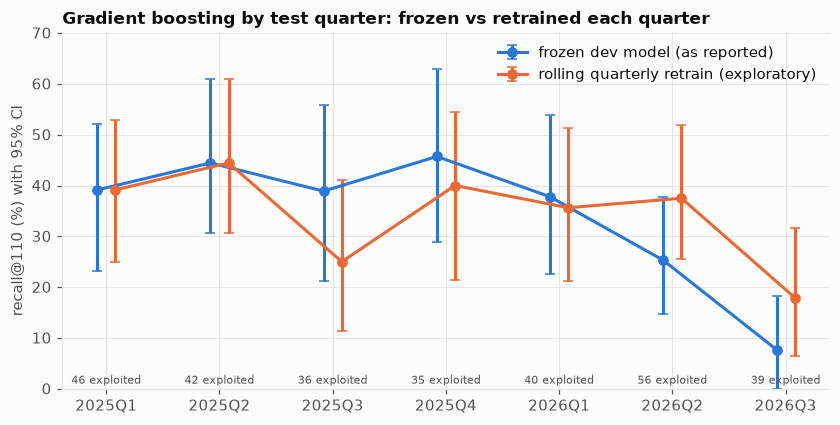

In [11]:
roll = T("06x_rolling_retrain")
q = roll[roll["period"].str.contains("Q")].reset_index(drop=True)
display(roll[["period", "positives", "frozen @110", "rolling @110", "rolling - frozen (pts)", "diff CI", "P(rolling better)",
              "train cut (published before)", "train CVEs", "train positives", "of which test-period positives"]].set_index("period"))
fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(q))
for name, c, off in [("frozen", BLUE, -0.08), ("rolling", ORANGE, 0.08)]:
    ax.errorbar(x + off, q[name], yerr=[q[name] - q[f"{name} lo"], q[f"{name} hi"] - q[name]], color=c, fmt="o-", lw=2, capsize=3,
                label="frozen dev model (as reported)" if name == "frozen" else "rolling quarterly retrain (exploratory)")
for xi, n in zip(x, q["positives"]): ax.annotate(f"{n} exploited", (xi, 1), ha="center", fontsize=7.5, color=INK2)
ax.set_xticks(x, q["period"]); ax.set_ylim(0, 70); ax.set_ylabel("recall@110 (%) with 95% CI")
ax.legend(frameon=False, loc="upper right"); ax.set_title("Gradient boosting by test quarter: frozen vs retrained each quarter", loc="left")
save(fig, "06_06_rolling_retrain")

**Takeaway**: **Over the whole test period, retraining every quarter is a wash: 34.7% [29–40] vs 33.7% for the frozen model (+1.0 [−3.3, +5.6])**. The timing matters, though. In 2025 retraining **hurt slightly** (−4.4 [−9.7, +0.7]; 2025Q3 −13.9), because the newest 2025 data added noise. In **2026 it helped: +7.4 [+0.0, +15.2] (31.3% vs 23.9%)**. In 2026Q2 that was +12.2 [+3.1, +22.4] (37.5% vs 25.3%), and 2026Q3 was 17.9% vs 7.7%. 2025Q2 is identical by construction (the rolling model trains on exactly dev), which confirms the simulation. The 90-day label delay means a retrain always lags at least a quarter behind. **For the CISO: retraining is cheap insurance against drift, not a performance boost in stable periods**. Retraining **plus re-checking K against monthly volume** matters more: K = 110 is a shrinking share of a growing CVE stream.

## 9. Limitations
* **CNA CVSS is not fully day-0** (pre-test check 7a): CNAs later changed their own vector for 5.5% of exploited vs
  1.9% of other CVEs; 2 exploited CVEs crossed 9.0 only later. Using the first known vector cost ~0.8 points on dev
  (a lower bound). Description edits are label-correlated too (Decision 10e), though re-scoring with the earliest
  text did not inflate results on dev.
* **Uncertain day-0 phrases** (check 7b): on dev, removing them cost the fusion 2.0 points and helped gradient boosting
  (+0.4). Test has **no** uncertain rows (57 phrases verified at publication, 6 removed), so the test check was N/A.
* **EPSS comparison**: lookahead favours EPSS; different target (30-day activity); v3 → v4 switch inside test; EPSS is
  *assumed* to use KEV (documentation not reachable) → Section 5.
* **Label = KEV listing**, which is CISA's selection of exploited CVEs (US-government-relevant products, evidence
  required); exploitation never reported to CISA counts as "not exploited".
* **Drift**: recall fell to 23.9% in 2026 (Section 7); K = 110 was fixed from 2022–24 volumes and covers 1.6% of a 2026 month.
* **Small numbers**: 294 exploited CVEs over 20 months; quarterly CIs are ±15–20 points.
* **Calibration** degrades out of time: average over-prediction as the base rate fell, under-prediction in the top 0.5%.

## 10. Side-by-side: every method, validation (dry run, train-only fit) and test

In [12]:
dry = T("06dry_recall").set_index("method")
methods_all = [HEAD, ALT, EPSS7, EPSS1, "phrase, then CVSS (CNA)", "CVSS (CNA) ranking", "generous CVSS (fallback) ranking", EPSS0, "random"]
kind = {HEAD: "model (headline)", ALT: "model (alternative)", EPSS7: "benchmark (lookahead)", EPSS1: "benchmark",
        EPSS0: "benchmark (like-for-like)", "phrase, then CVSS (CNA)": "day-0 rule (best)", "CVSS (CNA) ranking": "day-0 rule (today)",
        "generous CVSS (fallback) ranking": "rule with hindsight", "random": "reference"}
rows = []
for m in methods_all:
    r = {"method": m, "type": kind[m]}
    if m == "random":
        r.update({"val recall@110": f"{dry.loc[m, 'recall@110']:.1f}", "test recall@110 [95% CI]": f"{rec.loc[m, 'recall@110']:.1f}",
                  "test recall@305 [95% CI]": f"{rec.loc[m, 'recall@305']:.1f}"})
    else:
        r.update({"val recall@110": dry.loc[m, "recall@110 [95% CI]"], "test recall@110 [95% CI]": rec.loc[m, "recall@110 [95% CI]"],
                  "test recall@305 [95% CI]": rec.loc[m, "recall@305 [95% CI]"],
                  "test 2025 @110": dy.loc[2025, f"{m} @110"] if f"{m} @110" in dy else "",
                  "test 2026 @110": dy.loc[2026, f"{m} @110"] if f"{m} @110" in dy else "",
                  "not yet in KEV @110": nyk.loc[EPSS7, f"{m} @110"]})
    r["test PR-AUC"] = round(rec.loc[m, "PR-AUC"], 3)
    rows.append(r)
rows.append({"method": "gradient boosting, rolling quarterly retrain", "type": "exploratory (post-test)",
             "test recall@110 [95% CI]": roll.set_index("period").loc["all test", "rolling @110"],
             "test 2025 @110": roll.set_index("period").loc["2025", "rolling @110"], "test 2026 @110": roll.set_index("period").loc["2026", "rolling @110"]})
final = pd.DataFrame(rows).set_index("method").astype(object).fillna("")
display(final); final.to_csv(TAB / "06_final_comparison.csv")

,type,val recall@110,test recall@110 [95% CI],test recall@305 [95% CI],test 2025 @110,test 2026 @110,not yet in KEV @110,test PR-AUC
method,,,,,,,,
gradient boosting (headline),model (headline),47.1 [36–60],33.7 [28–39],49.3 [44–55],41.9 [34–50],23.9 [17–32],30.4 [24–37],0.053
late fusion (alternative),model (alternative),42.6 [30–55],29.3 [24–35],48.0 [43–54],39.1 [31–47],17.8 [12–25],23.8 [17–29],0.048
"EPSS (first score, <=7 d after pub)",benchmark (lookahead),36.8 [25–48],29.6 [24–35],45.4 [40–51],29.6 [23–37],29.6 [21–37],14.6 [9–20],0.069
EPSS (score by day 1),benchmark,36.8 [25–49],29.6 [24–35],45.1 [39–51],29.6 [23–37],29.6 [21–37],14.6 [9–20],0.069
"phrase, then CVSS (CNA)",day-0 rule (best),28.1 [17–38],25.2 [20–30],42.2 [36–48],29.5 [22–37],20.0 [13–27],29.4 [23–36],0.042
CVSS (CNA) ranking,day-0 rule (today),23.7 [13–33],18.6 [14–23],36.1 [30–41],19.2 [13–26],17.8 [11–25],22.1 [16–28],0.014
generous CVSS (fallback) ranking,rule with hindsight,15.1 [6–25],17.8 [13–22],31.6 [26–37],,,20.3 [14–27],0.015
EPSS (day-0 score only),benchmark (like-for-like),2.9 [0–8],5.1 [3–8],9.9 [7–14],,,6.5 [3–10],0.003
random,reference,3.5,2.2,6.2,,,,0.003


**Takeaway**: **Gradient boosting (the pre-registered headline) is the best day-0 method on test: 33.7% at 110 patches a month vs 25.2% for the best rule and 18.6% for today's CVSS ranking. At the CVSS ≥ 9 rule's own 385 patches it catches 51.7% vs 41.2%.** It is level-to-ahead of EPSS overall (29.6%; +4.1, not significant). On exploited CVEs not yet in KEV when EPSS scored them, it is about twice EPSS (30.4% vs 14.6%). Performance fell from 47.1% (val) and 41.9% (2025) to 23.9% in 2026. Exploratory analysis attributes this mainly to volume growth against a fixed K and to more CVEs from KEV-history vendors competing for the slots. Quarterly retraining recovers part of the 2026 loss (31.3%).